Note: you may need to restart the kernel to use updated packages.


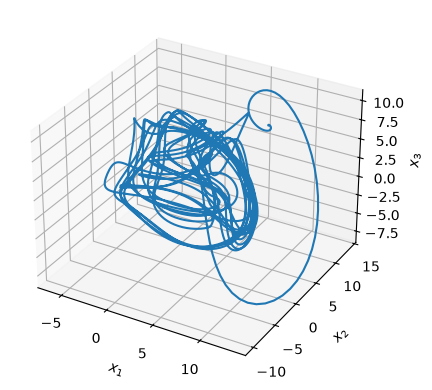

In [6]:
%pip install scipy
from scipy.integrate import odeint
import matplotlib.pyplot as plt
import numpy as np
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp

# These are our constants
N = 5  # Number of variables
F = 8  # Forcing


def L96(x, t):
    """Lorenz 96 model with constant forcing"""
    return (np.roll(x, -1) - np.roll(x, 2)) * np.roll(x, 1) - x + F


x0 = F * np.ones(N)  # Initial state (equilibrium)
x0[0] += 0.01  # Add small perturbation to the first variable
t = np.arange(0.0, 30.0, 0.01)

x = odeint(L96, x0, t)

# Plot the first three variables
fig = plt.figure()
ax = fig.add_subplot(projection="3d")
ax.plot(x[:, 0], x[:, 1], x[:, 2])
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$x_3$")
plt.show()

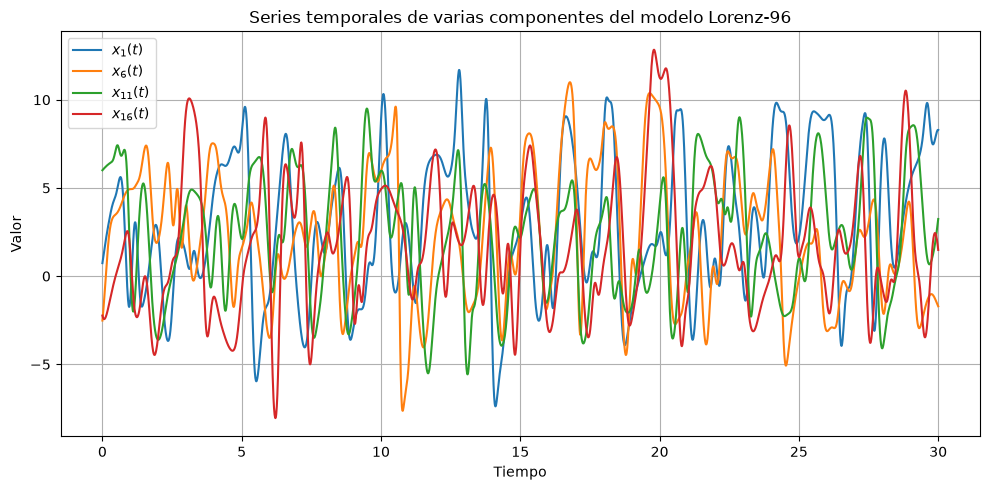

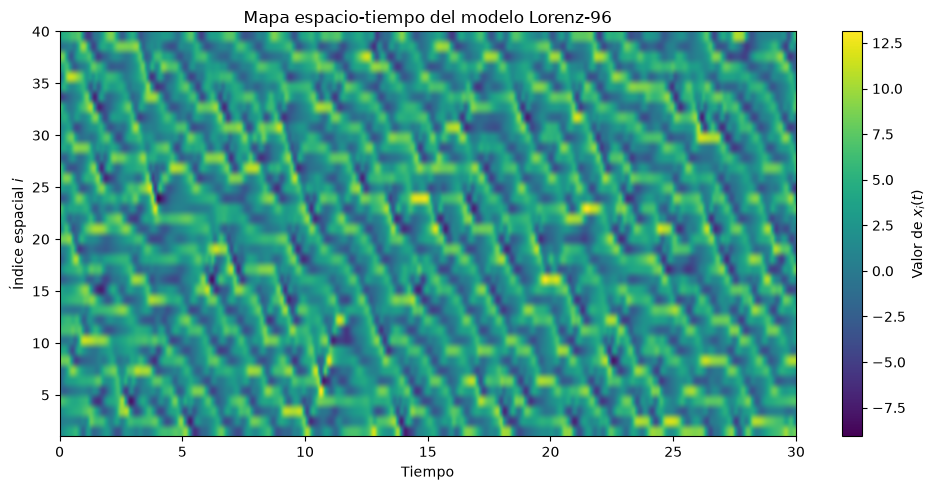

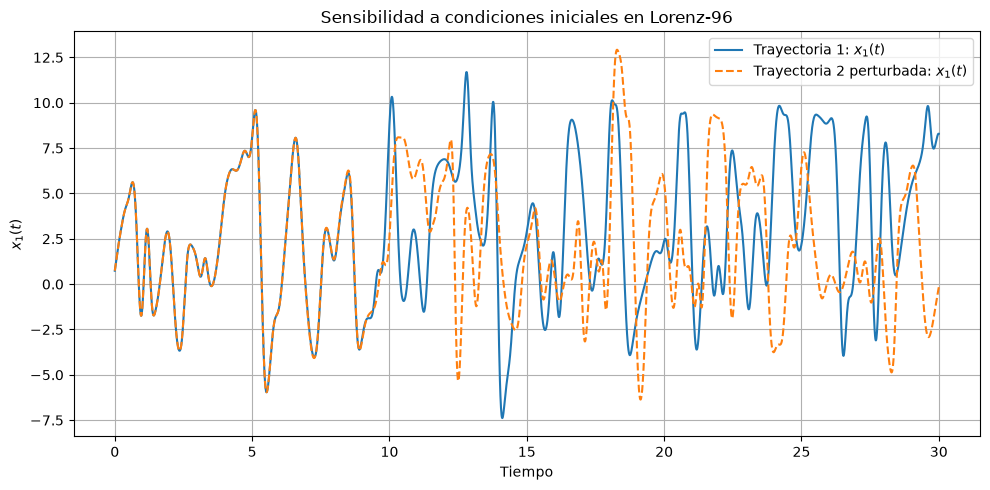

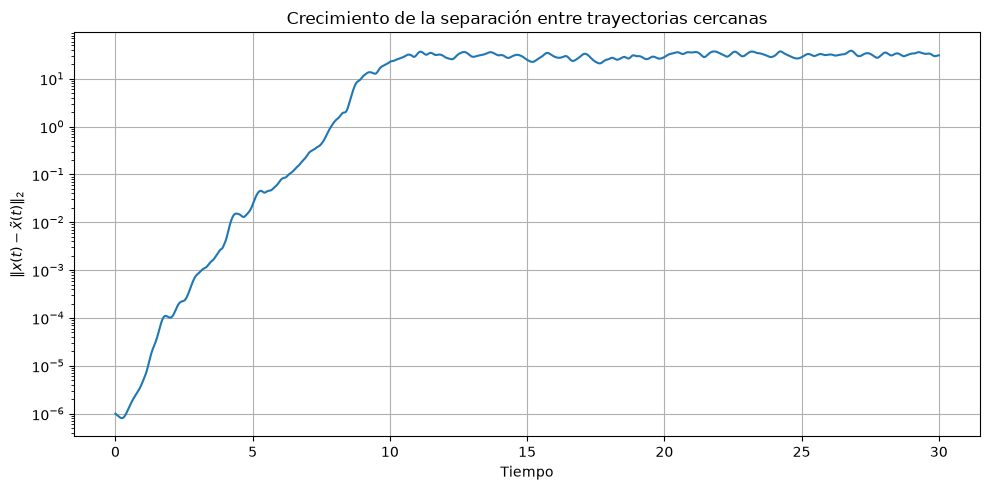

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# MODELO LORENZ-96
# ============================================================

def lorenz96_rhs(x, F=8.0):
    """
    Lado derecho del sistema de Lorenz-96:
        dx_i/dt = x_{i-1}(x_{i+1} - x_{i-2}) - x_i + F
    con índices cíclicos.
    """
    d = len(x)
    dxdt = np.zeros(d)
    for i in range(d):
        dxdt[i] = x[(i - 1) % d] * (x[(i + 1) % d] - x[(i - 2) % d]) - x[i] + F
    return dxdt


def rk4_step(x, dt, F=8.0):
    k1 = lorenz96_rhs(x, F)
    k2 = lorenz96_rhs(x + 0.5 * dt * k1, F)
    k3 = lorenz96_rhs(x + 0.5 * dt * k2, F)
    k4 = lorenz96_rhs(x + dt * k3, F)
    return x + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)


def integrate_l96(x0, n_steps, dt, F=8.0):
    x = np.array(x0, dtype=float)
    traj = np.zeros((n_steps + 1, len(x0)))
    traj[0] = x
    for n in range(n_steps):
        x = rk4_step(x, dt, F)
        traj[n + 1] = x
    return traj


def spinup(x0, n_spin=2000, dt=0.01, F=8.0):
    x = np.array(x0, dtype=float)
    for _ in range(n_spin):
        x = rk4_step(x, dt, F)
    return x


# ============================================================
# PARÁMETROS
# ============================================================

d = 40
F = 8.0
dt = 0.01
n_steps = 3000

# Estado inicial y spin-up
x0 = F * np.ones(d)
x0[0] += 0.01
x0 = spinup(x0, n_spin=3000, dt=dt, F=F)

# Trayectoria principal
traj = integrate_l96(x0, n_steps, dt, F)
t = np.arange(n_steps + 1) * dt

# ============================================================
# FIGURA 1: SERIES TEMPORALES DE VARIAS COMPONENTES
# ============================================================

plt.figure(figsize=(10, 5))
for i in [0, 5, 10, 15]:
    plt.plot(t, traj[:, i], label=fr"$x_{{{i+1}}}(t)$")
plt.xlabel("Tiempo")
plt.ylabel("Valor")
plt.title("Series temporales de varias componentes del modelo Lorenz-96")
plt.legend()
plt.grid(True)
plt.tight_layout()

# ============================================================
# FIGURA 2: MAPA ESPACIO-TIEMPO
# ============================================================

plt.figure(figsize=(10, 5))
plt.imshow(
    traj.T,
    aspect="auto",
    origin="lower",
    extent=[t[0], t[-1], 1, d]
)
plt.colorbar(label="Valor de $x_i(t)$")
plt.xlabel("Tiempo")
plt.ylabel("Índice espacial $i$")
plt.title("Mapa espacio-tiempo del modelo Lorenz-96")
plt.tight_layout()

# ============================================================
# FIGURA 3: DOS TRAYECTORIAS CON CONDICIONES INICIALES CERCANAS
# ============================================================

x0_pert = x0.copy()
x0_pert[0] += 1e-6

traj_pert = integrate_l96(x0_pert, n_steps, dt, F)

plt.figure(figsize=(10, 5))
plt.plot(t, traj[:, 0], label="Trayectoria 1: $x_1(t)$")
plt.plot(t, traj_pert[:, 0], "--", label="Trayectoria 2 perturbada: $x_1(t)$")
plt.xlabel("Tiempo")
plt.ylabel("$x_1(t)$")
plt.title("Sensibilidad a condiciones iniciales en Lorenz-96")
plt.legend()
plt.grid(True)
plt.tight_layout()

# ============================================================
# FIGURA 4: CRECIMIENTO DE LA DISTANCIA ENTRE TRAYECTORIAS
# ============================================================

dist = np.linalg.norm(traj - traj_pert, axis=1)

plt.figure(figsize=(10, 5))
plt.semilogy(t, dist)
plt.xlabel("Tiempo")
plt.ylabel(r"$\|x(t)-\tilde{x}(t)\|_2$")
plt.title("Crecimiento de la separación entre trayectorias cercanas")
plt.grid(True)
plt.tight_layout()

plt.show()

Note: you may need to restart the kernel to use updated packages.


C:\Users\alave\AppData\Local\Temp\ipykernel_28580\4106500802.py:229: OptimizeWarning: Unknown solver options: disp
  result = minimize(



SENSIBILIDAD AL NÚMERO DE VARIABLES OBSERVADAS
     n_obs_vars |    RMSE traj bg |    RMSE traj an
----------------------------------------------------------------------
             10 |        3.260614 |        1.164496
             15 |        2.913396 |        0.486163
             20 |        2.952360 |        0.285753
             30 |        2.822854 |        0.242504
             40 |        3.415380 |        0.240757

SENSIBILIDAD AL RUIDO OBSERVACIONAL
      sigma_obs |    RMSE traj bg |    RMSE traj an
----------------------------------------------------------------------
           0.25 |        3.542102 |        0.075610
            0.5 |        3.188546 |        0.218788
            1.0 |        3.321386 |        0.289592
            1.5 |        3.519433 |        0.435583
            2.0 |        3.853513 |        2.210438

SENSIBILIDAD A LA LONGITUD DE LA VENTANA
        n_steps |    RMSE traj bg |    RMSE traj an
-------------------------------------------------------

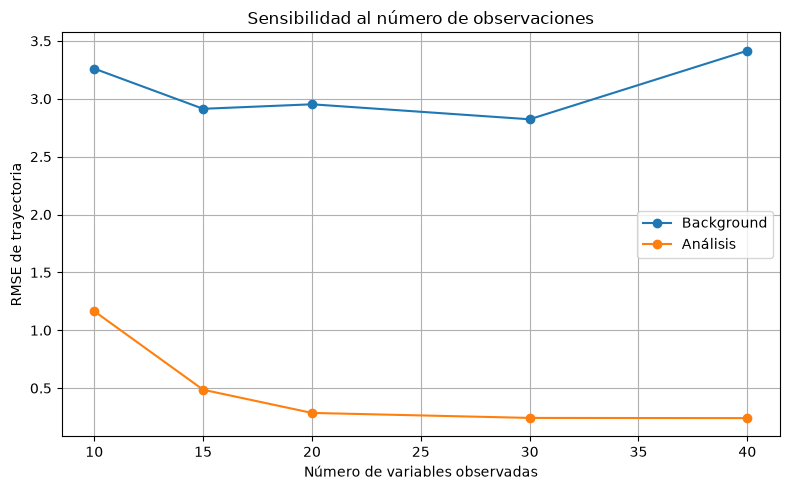

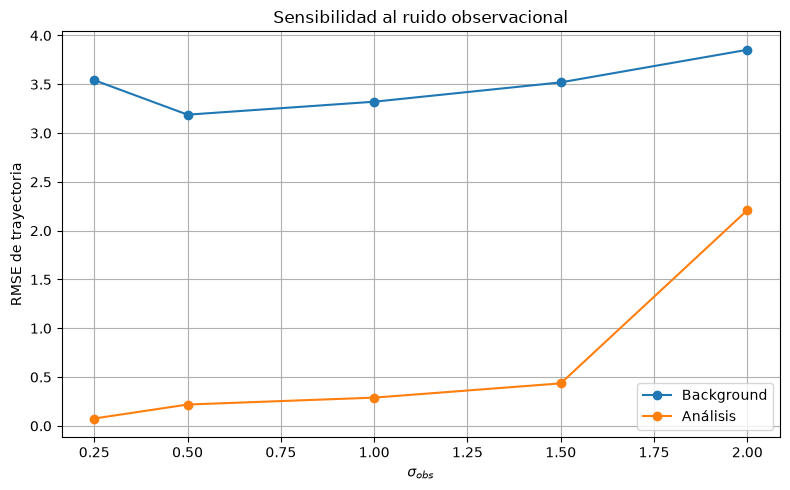

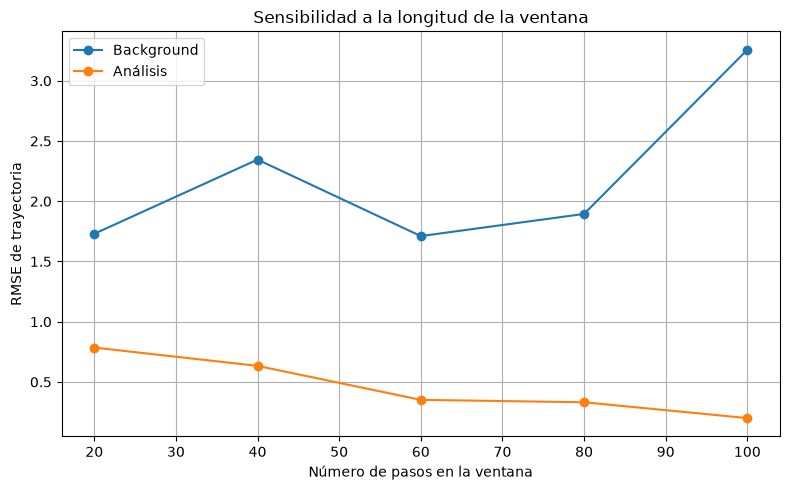

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
%pip install jax
import jax
import jax.numpy as jnp


# ============================================================
# CONFIGURACIÓN GLOBAL
# ============================================================

SEED = 1234
rng = np.random.default_rng(SEED)


# ============================================================
# 1. MODELO DE LORENZ-96
# ============================================================

def lorenz96_rhs(x, F=8.0):
    """
    Lado derecho del sistema de Lorenz-96:
        dx_j/dt = (x_{j+1} - x_{j-2}) x_{j-1} - x_j + F
    con índices cíclicos.
    """
    return (jnp.roll(x, -1) - jnp.roll(x, 2)) * jnp.roll(x, 1) - x + F


def rk4_step(x, dt, F=8.0):
    """
    Un paso RK4.
    """
    k1 = lorenz96_rhs(x, F)
    k2 = lorenz96_rhs(x + 0.5 * dt * k1, F)
    k3 = lorenz96_rhs(x + 0.5 * dt * k2, F)
    k4 = lorenz96_rhs(x + dt * k3, F)
    return x + (dt / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)


def integrate_l96(x0, n_steps, dt, F=8.0):
    """
    Integra el modelo y devuelve la trayectoria completa:
        traj.shape = (n_steps+1, d)
    """
    x = jnp.array(x0)
    traj = [x]
    for _ in range(n_steps):
        x = rk4_step(x, dt, F)
        traj.append(x)
    return jnp.stack(traj, axis=0)


def spinup_state(x0, n_spin, dt, F=8.0):
    """
    Spin-up para entrar en régimen caótico.
    """
    x = jnp.array(x0)
    for _ in range(n_spin):
        x = rk4_step(x, dt, F)
    return x


# ============================================================
# 2. OPERADOR DE OBSERVACIÓN
# ============================================================

def build_obs_indices(d, n_obs_vars):
    """
    Selecciona n_obs_vars componentes del estado, uniformemente repartidas.
    """
    if n_obs_vars > d:
        raise ValueError("n_obs_vars no puede ser mayor que d.")
    return np.linspace(0, d - 1, n_obs_vars, dtype=int)


def H_of_x(x, obs_idx):
    """
    Operador de observación lineal: selecciona componentes.
    """
    return x[obs_idx]


# ============================================================
# 3. EXPERIMENTO GEMELO
# ============================================================

def generate_truth(
    d=40,
    F=8.0,
    dt=0.01,
    n_steps=100,
    n_spin=3000
):
    """
    Genera la trayectoria verdadera.
    """
    x0 = F * np.ones(d)
    x0[0] += 0.01
    x0_true = np.array(spinup_state(jnp.array(x0), n_spin, dt, F))
    truth = np.array(integrate_l96(jnp.array(x0_true), n_steps, dt, F))
    return x0_true, truth


def generate_observations(truth, obs_idx, obs_every, sigma_obs, rng):
    """
    Genera observaciones sintéticas:
        y_k = H(x_true_k) + eps_k
    """
    n_steps = truth.shape[0] - 1
    obs_times = np.arange(0, n_steps + 1, obs_every)
    y_obs = []

    for k in obs_times:
        yk = truth[k, obs_idx] + sigma_obs * rng.standard_normal(len(obs_idx))
        y_obs.append(yk)

    return obs_times, np.array(y_obs)


def generate_background(x0_true, sigma_b, rng):
    """
    Genera background:
        x_b = x0_true + eta
    """
    return x0_true + sigma_b * rng.standard_normal(len(x0_true))


# ============================================================
# 4. MATRICES DE COVARIANZA
# ============================================================

def build_diagonal_covariances(d, m, sigma_b, sigma_obs):
    """
    B = sigma_b^2 I, R = sigma_obs^2 I
    """
    B = (sigma_b ** 2) * np.eye(d)
    R = (sigma_obs ** 2) * np.eye(m)
    B_inv = np.eye(d) / (sigma_b ** 2)
    R_inv = np.eye(m) / (sigma_obs ** 2)
    return B, R, B_inv, R_inv


# ============================================================
# 5. FUNCIÓN DE COSTE 4D-VAR
# ============================================================

def build_4dvar_cost(xb, B_inv, y_obs, obs_times, obs_idx, R_inv, n_steps, dt, F=8.0):
    """
    Construye la función de coste:
        J(x0) = Jb(x0) + Jo(x0)
    con strong-constraint 4D-Var.
    """
    xb = jnp.array(xb)
    B_inv = jnp.array(B_inv)
    y_obs = jnp.array(y_obs)
    obs_times = list(map(int, np.array(obs_times)))
    obs_idx = jnp.array(obs_idx)
    R_inv = jnp.array(R_inv)

    obs_map = {t: i for i, t in enumerate(obs_times)}

    def cost(x0):
        traj = integrate_l96(x0, n_steps, dt, F)

        dx = x0 - xb
        Jb = 0.5 * dx @ B_inv @ dx

        Jo = 0.0
        for t in obs_times:
            i = obs_map[t]
            innov = y_obs[i] - traj[t][obs_idx]
            Jo = Jo + 0.5 * innov @ R_inv @ innov

        return Jb + Jo

    return cost


# ============================================================
# 6. TEST DEL GRADIENTE
# ============================================================

def gradient_test(cost_fun, x, rng, n_alphas=8):
    """
    Comprueba que:
        (J(x + alpha h) - J(x)) / (alpha * gradJ(x)^T h) -> 1
    """
    x = jnp.array(x)
    grad_fun = jax.grad(cost_fun)

    h = rng.standard_normal(len(x))
    h = h / np.linalg.norm(h)

    grad_x = np.array(grad_fun(x))
    denom = grad_x @ h

    if abs(denom) < 1e-14:
        raise RuntimeError("Denominador demasiado pequeño en gradient test.")

    alphas = 10.0 ** (-np.arange(1, n_alphas + 1))
    ratios = []

    Jx = float(cost_fun(x))
    for alpha in alphas:
        Jxa = float(cost_fun(x + alpha * h))
        ratio = (Jxa - Jx) / (alpha * denom)
        ratios.append(ratio)

    return alphas, np.array(ratios)


# ============================================================
# 7. MINIMIZACIÓN
# ============================================================

def minimize_4dvar(cost_fun, x0_guess, maxiter=200, verbose=True):
    """
    Minimiza J usando L-BFGS-B.
    """
    grad_fun = jax.grad(cost_fun)

    def fun_np(x):
        return float(cost_fun(jnp.array(x)))

    def jac_np(x):
        return np.array(grad_fun(jnp.array(x)), dtype=float)

    result = minimize(
        fun=fun_np,
        x0=np.array(x0_guess, dtype=float),
        jac=jac_np,
        method="L-BFGS-B",
        options={"maxiter": maxiter, "disp": verbose}
    )
    return result


# ============================================================
# 8. MÉTRICAS
# ============================================================

def rmse(a, b):
    return np.sqrt(np.mean((np.array(a) - np.array(b)) ** 2))


def trajectory_rmse(traj_a, traj_b):
    """
    Error RMSE temporal instantáneo.
    """
    return np.sqrt(np.mean((np.array(traj_a) - np.array(traj_b)) ** 2, axis=1))


# ============================================================
# 9. EXPERIMENTO BASE
# ============================================================

def run_base_experiment(
    d=40,
    F=8.0,
    dt=0.01,
    n_steps=100,
    obs_every=5,
    n_obs_vars=20,
    sigma_obs=1.0,
    sigma_b=1.5,
    maxiter=200,
    make_plots=True,
    verbose=True
):
    """
    Ejecuta un experimento 4D-Var completo.
    """
    # -------------------------
    # Verdad
    # -------------------------
    x0_true, truth = generate_truth(
        d=d,
        F=F,
        dt=dt,
        n_steps=n_steps,
        n_spin=3000
    )

    # -------------------------
    # Observaciones
    # -------------------------
    obs_idx = build_obs_indices(d, n_obs_vars)
    obs_times, y_obs = generate_observations(
        truth=truth,
        obs_idx=obs_idx,
        obs_every=obs_every,
        sigma_obs=sigma_obs,
        rng=rng
    )

    # -------------------------
    # Background
    # -------------------------
    xb = generate_background(x0_true, sigma_b, rng)

    # -------------------------
    # Covarianzas
    # -------------------------
    _, _, B_inv, R_inv = build_diagonal_covariances(
        d=d, m=len(obs_idx), sigma_b=sigma_b, sigma_obs=sigma_obs
    )

    # -------------------------
    # Coste y gradient test
    # -------------------------
    cost_fun = build_4dvar_cost(
        xb=xb,
        B_inv=B_inv,
        y_obs=y_obs,
        obs_times=obs_times,
        obs_idx=obs_idx,
        R_inv=R_inv,
        n_steps=n_steps,
        dt=dt,
        F=F
    )

    alphas, ratios = gradient_test(cost_fun, xb, rng)

    # -------------------------
    # Minimización
    # -------------------------
    result = minimize_4dvar(cost_fun, xb, maxiter=maxiter, verbose=verbose)
    xa0 = result.x

    # -------------------------
    # Trayectorias
    # -------------------------
    traj_b = np.array(integrate_l96(jnp.array(xb), n_steps, dt, F))
    traj_a = np.array(integrate_l96(jnp.array(xa0), n_steps, dt, F))

    # -------------------------
    # Métricas
    # -------------------------
    rmse_b0 = rmse(xb, x0_true)
    rmse_a0 = rmse(xa0, x0_true)

    rmse_traj_b = rmse(traj_b, truth)
    rmse_traj_a = rmse(traj_a, truth)

    reduction_initial = 100.0 * (rmse_b0 - rmse_a0) / rmse_b0
    reduction_traj = 100.0 * (rmse_traj_b - rmse_traj_a) / rmse_traj_b

    if verbose:
        print("\n" + "=" * 60)
        print("RESULTADOS DEL EXPERIMENTO BASE")
        print("=" * 60)
        print(f"Dimensión del sistema:              {d}")
        print(f"Forzamiento F:                      {F}")
        print(f"Paso temporal dt:                   {dt}")
        print(f"Número de pasos:                    {n_steps}")
        print(f"Observaciones cada:                 {obs_every} pasos")
        print(f"Número de variables observadas:     {n_obs_vars}")
        print(f"Sigma_obs:                          {sigma_obs}")
        print(f"Sigma_b:                            {sigma_b}")
        print(f"Iteraciones optimización:           {result.nit}")
        print(f"Convergencia del optimizador:       {result.success}")
        print(f"Mensaje del optimizador:            {result.message}")
        print(f"RMSE inicial background:            {rmse_b0:.6f}")
        print(f"RMSE inicial análisis:              {rmse_a0:.6f}")
        print(f"Reducción RMSE inicial (%):         {reduction_initial:.2f}")
        print(f"RMSE trayectoria background:        {rmse_traj_b:.6f}")
        print(f"RMSE trayectoria análisis:          {rmse_traj_a:.6f}")
        print(f"Reducción RMSE trayectoria (%):     {reduction_traj:.2f}")

    if make_plots:
        plot_base_results(
            truth, traj_b, traj_a, obs_times, y_obs, obs_idx,
            alphas, ratios
        )

    return {
        "x0_true": x0_true,
        "truth": truth,
        "obs_idx": obs_idx,
        "obs_times": obs_times,
        "y_obs": y_obs,
        "xb": xb,
        "xa0": xa0,
        "traj_b": traj_b,
        "traj_a": traj_a,
        "alphas": alphas,
        "ratios": ratios,
        "rmse_b0": rmse_b0,
        "rmse_a0": rmse_a0,
        "rmse_traj_b": rmse_traj_b,
        "rmse_traj_a": rmse_traj_a,
        "result": result,
    }


# ============================================================
# 10. FIGURAS
# ============================================================

def plot_base_results(truth, traj_b, traj_a, obs_times, y_obs, obs_idx, alphas, ratios):
    """
    Genera figuras básicas para el TFG.
    """
    t = np.arange(truth.shape[0])

    # ---------------------------------------
    # Figura 1: variable individual + observaciones
    # ---------------------------------------
    observed_var = int(obs_idx[0])
    pos_in_obs = np.where(obs_idx == observed_var)[0][0]

    plt.figure(figsize=(10, 5))
    plt.plot(t, truth[:, observed_var], label="Verdad")
    plt.plot(t, traj_b[:, observed_var], label="Background")
    plt.plot(t, traj_a[:, observed_var], label="Análisis")
    plt.plot(
        obs_times,
        y_obs[:, pos_in_obs],
        "o",
        label=f"Observaciones de x[{observed_var}]"
    )
    plt.xlabel("Paso temporal")
    plt.ylabel(f"x[{observed_var}]")
    plt.title("Trayectoria de una variable observada")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    # ---------------------------------------
    # Figura 2: error temporal de trayectoria
    # ---------------------------------------
    err_b = trajectory_rmse(traj_b, truth)
    err_a = trajectory_rmse(traj_a, truth)

    plt.figure(figsize=(10, 5))
    plt.plot(t, err_b, label="Error background")
    plt.plot(t, err_a, label="Error análisis")
    plt.xlabel("Paso temporal")
    plt.ylabel("RMSE instantáneo")
    plt.title("Evolución temporal del error")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    # ---------------------------------------
    # Figura 3: estado inicial
    # ---------------------------------------
    idx = np.arange(len(truth[0]))

    plt.figure(figsize=(10, 5))
    plt.plot(idx, truth[0], label="Estado inicial verdadero")
    plt.plot(idx, traj_b[0], label="Background")
    plt.plot(idx, traj_a[0], label="Análisis")
    plt.xlabel("Índice espacial")
    plt.ylabel("Valor")
    plt.title("Comparación del estado inicial")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    # ---------------------------------------
    # Figura 4: gradient test
    # ---------------------------------------
    plt.figure(figsize=(8, 5))
    plt.semilogx(alphas, ratios, "o-")
    plt.axhline(1.0, linestyle="--", label="Valor esperado = 1")
    plt.gca().invert_xaxis()   # α decrece hacia la derecha
    plt.xlabel(r"$\alpha$")
    plt.ylabel(r"$\Phi(\alpha)$")
    plt.title("Gradient test")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.show()


# ============================================================
# 11. SENSIBILIDAD
# ============================================================

def sensitivity_n_obs_vars(
    obs_var_list,
    d=40,
    F=8.0,
    dt=0.01,
    n_steps=100,
    obs_every=5,
    sigma_obs=1.0,
    sigma_b=1.5,
    maxiter=150
):
    """
    Sensibilidad respecto al número de variables observadas.
    """
    results = []

    for n_obs_vars in obs_var_list:
        out = run_base_experiment(
            d=d,
            F=F,
            dt=dt,
            n_steps=n_steps,
            obs_every=obs_every,
            n_obs_vars=n_obs_vars,
            sigma_obs=sigma_obs,
            sigma_b=sigma_b,
            maxiter=maxiter,
            make_plots=False,
            verbose=False
        )
        results.append({
            "n_obs_vars": n_obs_vars,
            "rmse_b0": out["rmse_b0"],
            "rmse_a0": out["rmse_a0"],
            "rmse_traj_b": out["rmse_traj_b"],
            "rmse_traj_a": out["rmse_traj_a"],
        })

    return results


def sensitivity_sigma_obs(
    sigma_obs_list,
    d=40,
    F=8.0,
    dt=0.01,
    n_steps=100,
    obs_every=5,
    n_obs_vars=20,
    sigma_b=1.5,
    maxiter=150
):
    """
    Sensibilidad respecto al ruido observacional.
    """
    results = []

    for sigma_obs in sigma_obs_list:
        out = run_base_experiment(
            d=d,
            F=F,
            dt=dt,
            n_steps=n_steps,
            obs_every=obs_every,
            n_obs_vars=n_obs_vars,
            sigma_obs=sigma_obs,
            sigma_b=sigma_b,
            maxiter=maxiter,
            make_plots=False,
            verbose=False
        )
        results.append({
            "sigma_obs": sigma_obs,
            "rmse_b0": out["rmse_b0"],
            "rmse_a0": out["rmse_a0"],
            "rmse_traj_b": out["rmse_traj_b"],
            "rmse_traj_a": out["rmse_traj_a"],
        })

    return results


def sensitivity_window_length(
    window_list,
    d=40,
    F=8.0,
    dt=0.01,
    obs_every=5,
    n_obs_vars=20,
    sigma_obs=1.0,
    sigma_b=1.5,
    maxiter=150
):
    """
    Sensibilidad respecto a la longitud de la ventana de asimilación.
    """
    results = []

    for n_steps in window_list:
        out = run_base_experiment(
            d=d,
            F=F,
            dt=dt,
            n_steps=n_steps,
            obs_every=obs_every,
            n_obs_vars=n_obs_vars,
            sigma_obs=sigma_obs,
            sigma_b=sigma_b,
            maxiter=maxiter,
            make_plots=False,
            verbose=False
        )
        results.append({
            "n_steps": n_steps,
            "rmse_b0": out["rmse_b0"],
            "rmse_a0": out["rmse_a0"],
            "rmse_traj_b": out["rmse_traj_b"],
            "rmse_traj_a": out["rmse_traj_a"],
        })

    return results


def plot_sensitivity_results(obs_results, sigma_results, window_results):
    """
    Figuras para los experimentos de sensibilidad.
    """
    # ---------------------------------------
    # 1) Número de variables observadas
    # ---------------------------------------
    x1 = [r["n_obs_vars"] for r in obs_results]
    y1b = [r["rmse_traj_b"] for r in obs_results]
    y1a = [r["rmse_traj_a"] for r in obs_results]

    plt.figure(figsize=(8, 5))
    plt.plot(x1, y1b, "o-", label="Background")
    plt.plot(x1, y1a, "o-", label="Análisis")
    plt.xlabel("Número de variables observadas")
    plt.ylabel("RMSE de trayectoria")
    plt.title("Sensibilidad al número de observaciones")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    # ---------------------------------------
    # 2) Ruido observacional
    # ---------------------------------------
    x2 = [r["sigma_obs"] for r in sigma_results]
    y2b = [r["rmse_traj_b"] for r in sigma_results]
    y2a = [r["rmse_traj_a"] for r in sigma_results]

    plt.figure(figsize=(8, 5))
    plt.plot(x2, y2b, "o-", label="Background")
    plt.plot(x2, y2a, "o-", label="Análisis")
    plt.xlabel(r"$\sigma_{obs}$")
    plt.ylabel("RMSE de trayectoria")
    plt.title("Sensibilidad al ruido observacional")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    # ---------------------------------------
    # 3) Longitud de ventana
    # ---------------------------------------
    x3 = [r["n_steps"] for r in window_results]
    y3b = [r["rmse_traj_b"] for r in window_results]
    y3a = [r["rmse_traj_a"] for r in window_results]

    plt.figure(figsize=(8, 5))
    plt.plot(x3, y3b, "o-", label="Background")
    plt.plot(x3, y3a, "o-", label="Análisis")
    plt.xlabel("Número de pasos en la ventana")
    plt.ylabel("RMSE de trayectoria")
    plt.title("Sensibilidad a la longitud de la ventana")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.show()


# ============================================================
# 12. IMPRESIÓN EN FORMATO TABLA SIMPLE
# ============================================================

def print_sensitivity_table(title, rows, x_key):
    print("\n" + "=" * 70)
    print(title)
    print("=" * 70)
    print(f"{x_key:>15} | {'RMSE traj bg':>15} | {'RMSE traj an':>15}")
    print("-" * 70)
    for r in rows:
        print(f"{str(r[x_key]):>15} | {r['rmse_traj_b']:>15.6f} | {r['rmse_traj_a']:>15.6f}")


# ============================================================
# 13. MAIN
# ============================================================

if __name__ == "__main__":
    # --------------------------------------------------------
    # EXPERIMENTO BASE
    # --------------------------------------------------------
    #base = run_base_experiment(
       # d=40,
        #F=8.0,
        #dt=0.01,
        #n_steps=100,
        #obs_every=5,
        #n_obs_vars=20,
        #sigma_obs=1.0,
        #sigma_b=1.5,
        #maxiter=200,
        #make_plots=True,
        #verbose=True
    #)

    # --------------------------------------------------------
    # SENSIBILIDAD: número de variables observadas
    # --------------------------------------------------------
    obs_results = sensitivity_n_obs_vars(
        obs_var_list=[10, 15, 20, 30, 40],
        d=40,
        F=8.0,
        dt=0.01,
        n_steps=100,
        obs_every=5,
        sigma_obs=1.0,
        sigma_b=1.5,
        maxiter=150
    )

    # --------------------------------------------------------
    # SENSIBILIDAD: ruido observacional
    # --------------------------------------------------------
    sigma_results = sensitivity_sigma_obs(
        sigma_obs_list=[0.25, 0.5, 1.0, 1.5, 2.0],
        d=40,
        F=8.0,
        dt=0.01,
        n_steps=100,
        obs_every=5,
        n_obs_vars=20,
        sigma_b=1.5,
        maxiter=150
    )

    # --------------------------------------------------------
    # SENSIBILIDAD: longitud de ventana
    # --------------------------------------------------------
    window_results = sensitivity_window_length(
        window_list=[20, 40, 60, 80, 100],
        d=40,
        F=8.0,
        dt=0.01,
        obs_every=5,
        n_obs_vars=20,
        sigma_obs=1.0,
        sigma_b=1.5,
        maxiter=150
    )

    # --------------------------------------------------------
    # Mostrar tablas
    # --------------------------------------------------------
    print_sensitivity_table(
        "SENSIBILIDAD AL NÚMERO DE VARIABLES OBSERVADAS",
        obs_results,
        "n_obs_vars"
    )

    print_sensitivity_table(
        "SENSIBILIDAD AL RUIDO OBSERVACIONAL",
        sigma_results,
        "sigma_obs"
    )

    print_sensitivity_table(
        "SENSIBILIDAD A LA LONGITUD DE LA VENTANA",
        window_results,
        "n_steps"
    )

    # --------------------------------------------------------
    # Figuras de sensibilidad
    # --------------------------------------------------------
    plot_sensitivity_results(obs_results, sigma_results, window_results)

dtype xb: float64 | dtype J: float64
[[1.00000000e-01 1.20317588e+00 2.03175883e-01]
 [1.00000000e-02 1.02055422e+00 2.05542191e-02]
 [1.00000000e-03 1.00205676e+00 2.05676166e-03]
 [1.00000000e-04 1.00020569e+00 2.05688815e-04]
 [1.00000000e-05 1.00002057e+00 2.05693688e-05]
 [1.00000000e-06 1.00000206e+00 2.05993995e-06]
 [1.00000000e-07 1.00000013e+00 1.33111052e-07]
 [1.00000000e-08 9.99999540e-01 4.60461830e-07]]


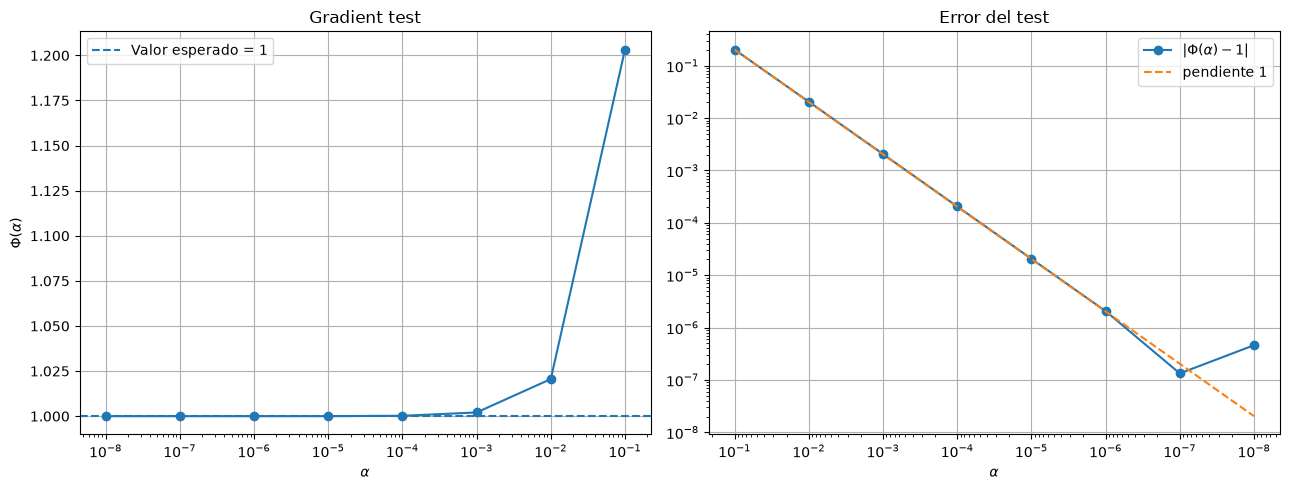

In [8]:
d, F, dt, n_steps = 40, 8.0, 0.01, 100
x0_true, truth = generate_truth(d=d, F=F, dt=dt, n_steps=n_steps)
obs_idx = build_obs_indices(d, 20)
obs_times, y_obs = generate_observations(truth, obs_idx, 5, 1.0, rng)
xb = generate_background(x0_true, 1.5, rng)
_, _, B_inv, R_inv = build_diagonal_covariances(d, len(obs_idx), 1.5, 1.0)
cost_fun = build_4dvar_cost(xb, B_inv, y_obs, obs_times, obs_idx, R_inv, n_steps, dt, F)

x_test = xb + 0.5 * rng.standard_normal(d)

# --- comprobación: si esto dice float32, el test no es fiable ---
print("dtype xb:", jnp.asarray(xb).dtype, "| dtype J:", cost_fun(jnp.asarray(x_test)).dtype)

alphas, ratios = gradient_test(cost_fun, x_test, rng)
print(np.c_[alphas, ratios, np.abs(ratios - 1)])   # tabla numérica

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].semilogx(alphas, ratios, "o-")
ax[0].axhline(1.0, linestyle="--", label="Valor esperado = 1")
ax[0].set_xlabel(r"$\alpha$"); ax[0].set_ylabel(r"$\Phi(\alpha)$")
plt.gca().invert_xaxis()
ax[0].set_title("Gradient test"); ax[0].legend(); ax[0].grid(True)

ax[1].loglog(alphas, np.abs(ratios - 1), "o-", label=r"$|\Phi(\alpha)-1|$")
ax[1].loglog(alphas, alphas * np.abs(ratios[0] - 1) / alphas[0], "--", label="pendiente 1")
ax[1].set_xlabel(r"$\alpha$"); ax[1].set_title("Error del test"); ax[1].legend(); ax[1].grid(True)

plt.tight_layout(); plt.show()